In [2]:
# Nama : Sendy Tegar Mahendra
# NIM  : TK0122004

# Klasifikasi Batik Keraton dengan 4 Kategori:
# 1. Batik Kawung
# 2. Batik Mega Mendung
# 3. Batik Parang
# 4. Batik Truntum

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Dense, Activation,Dropout,Conv2D, MaxPooling2D,BatchNormalization, Flatten,Input
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model, load_model, Sequential
from keras.callbacks import ModelCheckpoint
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
import os
import seaborn as sns
sns.set_style('darkgrid')
from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display, HTML
from keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop

### iterasi melalui folder untuk membuat dataframe dengan bentuk filepath label

In [15]:
sdir=r'C:\Users\hp\Computer Vision\Project Akhir Computer Vision\Batik-CNN\Dataset_Batik_Keraton'

filepaths=[]
labels=[]
classlist=os.listdir(sdir)
for klass in classlist:
    classpath=os.path.join(sdir,klass)
    if os.path.isdir(classpath):
        flist=os.listdir(classpath)
        for f in flist:
            fpath=os.path.join(classpath,f)
            filepaths.append(fpath)
            labels.append(klass)                   
Fseries= pd.Series(filepaths, name='filepaths')
Lseries=pd.Series(labels, name='labels')    
df=pd.concat([Fseries, Lseries], axis=1)
print (df.head())
print (df['labels'].value_counts())

                                           filepaths  labels
0  C:\Users\hp\Computer Vision\Project Akhir Comp...  Kawung
1  C:\Users\hp\Computer Vision\Project Akhir Comp...  Kawung
2  C:\Users\hp\Computer Vision\Project Akhir Comp...  Kawung
3  C:\Users\hp\Computer Vision\Project Akhir Comp...  Kawung
4  C:\Users\hp\Computer Vision\Project Akhir Comp...  Kawung
labels
Kawung          507
Mega_Mendung    472
Parang          426
Truntum         395
Name: count, dtype: int64


### split df into train_df, test_df and valid_df

In [16]:
train_split=.9
test_split=.05
dummy_split=test_split/(1-train_split)
train_df, dummy_df=train_test_split(df, train_size=train_split, shuffle=True, random_state=123)
test_df, valid_df=train_test_split(dummy_df, train_size=dummy_split, shuffle=True, random_state=123)
print ('train_df length: ', len(train_df), '  test_df length: ', len(test_df), '  valid_df length: ', len(valid_df))

train_df length:  1620   test_df length:  90   valid_df length:  90


### create train, test, valid  generators

In [17]:
height=224
width=224
channels=3
batch_size=64

img_shape=(height, width, channels)
img_size=(height, width)
length=len(test_df)
test_batch_size=sorted([int(length/n) for n in range(1,length+1) if length % n ==0 and length/n<=80],reverse=True)[0]  
test_steps=int(length/test_batch_size)
print ( 'test batch size: ' ,test_batch_size, '  test steps: ', test_steps)

gen=ImageDataGenerator(
    rescale=1./255,
    )
train_gen=gen.flow_from_dataframe( train_df, x_col='filepaths', y_col='labels', target_size=img_size, class_mode='categorical',
                                    color_mode='rgb', shuffle=True, batch_size=batch_size)

validgen=ImageDataGenerator(rescale=1./255)
valid_gen=validgen.flow_from_dataframe( valid_df, x_col='filepaths', y_col='labels', target_size=img_size, class_mode='categorical',
                                    color_mode='rgb', shuffle=True, batch_size=batch_size)

testgen=ImageDataGenerator(rescale=1./255)
test_gen=testgen.flow_from_dataframe( test_df, x_col='filepaths', y_col='labels', target_size=img_size, class_mode='categorical',
                                    color_mode='rgb', shuffle=False, batch_size=test_batch_size)

classes=list(train_gen.class_indices.keys())
print (classes)
class_count=len(classes)

test batch size:  45   test steps:  2
Found 1619 validated image filenames belonging to 4 classes.
Found 90 validated image filenames belonging to 4 classes.
Found 90 validated image filenames belonging to 4 classes.
['Kawung', 'Mega_Mendung', 'Parang', 'Truntum']


D:\Program Files\anaconda3\envs\ConvolutionalNeuralNetwork\lib\site-packages\keras\preprocessing\image.py:1139: UserWarning: Found 1 invalid image filename(s) in x_col="filepaths". These filename(s) will be ignored.
  warnings.warn(


### create function to show some image examples

In [18]:
def show_image_samples(gen):
    test_dict=test_gen.class_indices
    classes=list(test_dict.keys())    
    images,labels=next(gen) # get a sample batch from the generator 
    plt.figure(figsize=(20, 20))
    length=len(labels)
    if length<25:   #show maximum of 25 images
        r=length
    else:
        r=25
    for i in range(r):
        plt.subplot(5, 5, i + 1)
        image=images[i]
        plt.imshow(image)
        index=np.argmax(labels[i])
        class_name=classes[index]
        plt.title(class_name, color='blue', fontsize=16)
        plt.axis('off')
    plt.show()

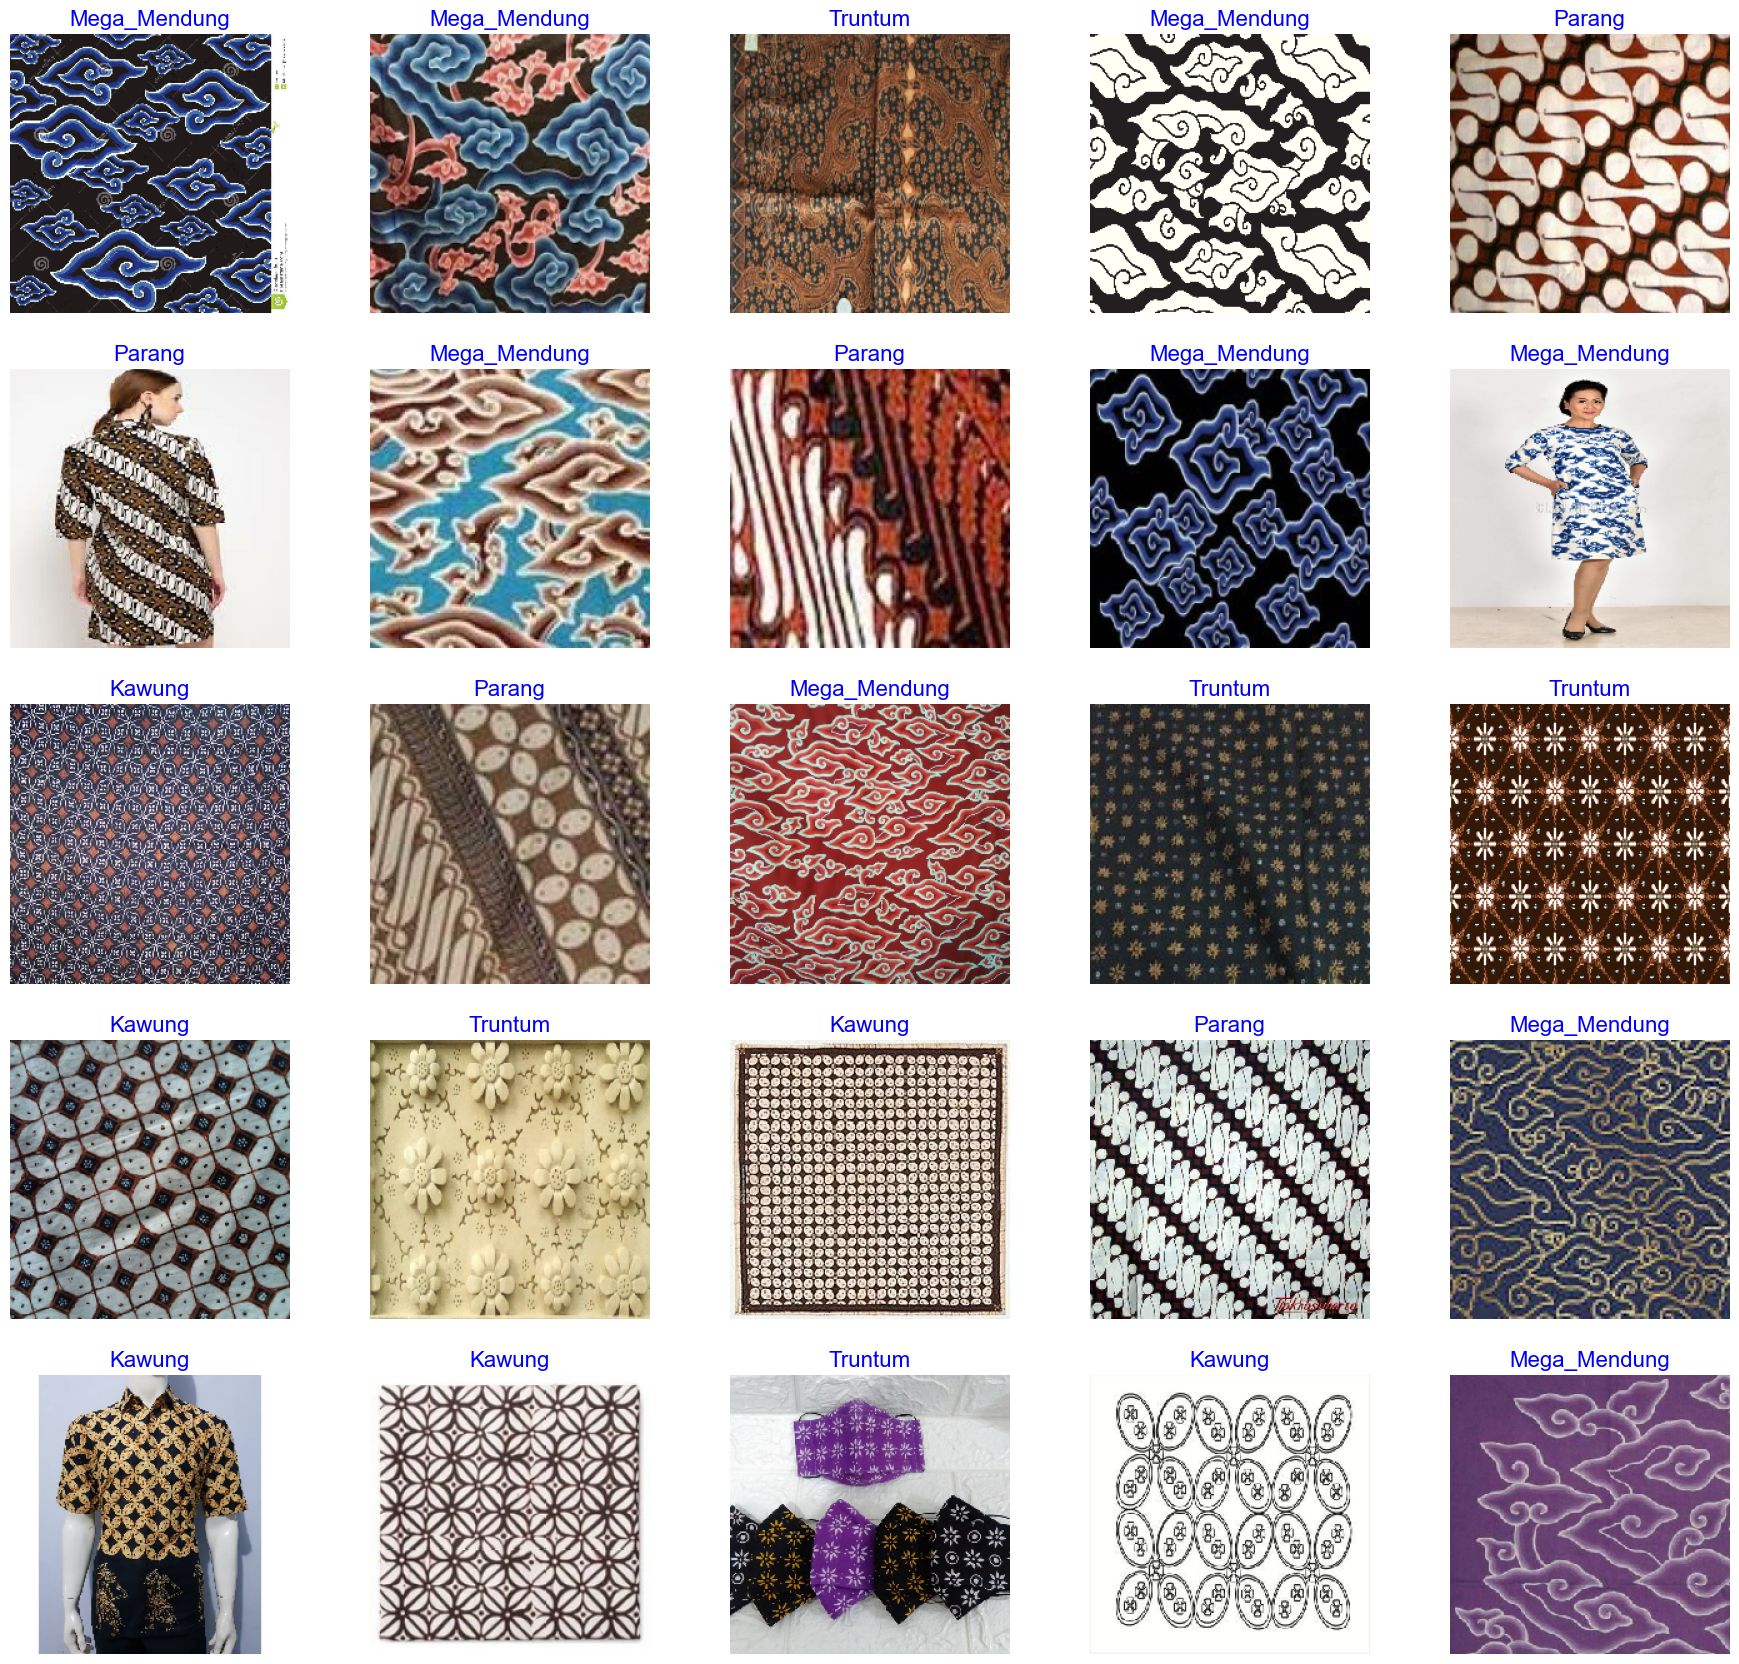

In [19]:
show_image_samples(train_gen)

### create the model

In [20]:
model_name = 'scratchCNN'

model = tf.keras.Sequential([
    tf.keras.Input(shape=img_shape),  # 
    tf.keras.layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu', strides=1),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(rate=0.4),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(class_count, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [21]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 224, 224, 32)      896       
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 112, 112, 32)     0         
 2D)                                                             
                                                                 
 dropout_1 (Dropout)         (None, 112, 112, 32)      0         
                                                                 
 flatten_1 (Flatten)         (None, 401408)            0         
                                                                 
 dense_1 (Dense)             (None, 4)                 1605636   
                                                                 
Total params: 1,606,532
Trainable params: 1,606,532
Non-trainable params: 0
____________________________________________

In [22]:
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

epochs = 100

mc = ModelCheckpoint('best_model.keras', monitor='val_accuracy', mode='max', save_best_only=True, verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

history = model.fit(
    x=train_gen,
    epochs=epochs,
    validation_data=valid_gen,
    callbacks=[early_stopping, reduce_lr, mc]
)


Epoch 1/100
 4/26 [===>..........................] - ETA: 3:21 - loss: 14.2357 - accuracy: 0.2500

D:\Program Files\anaconda3\envs\ConvolutionalNeuralNetwork\lib\site-packages\PIL\Image.py:1045: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


26/26 [==============================] - ETA: 0s - loss: 8.9697 - accuracy: 0.3422   
Epoch 1: val_accuracy improved from -inf to 0.33333, saving model to best_model.keras
26/26 [==============================] - 179s 6s/step - loss: 8.9697 - accuracy: 0.3422 - val_loss: 1.8712 - val_accuracy: 0.3333 - lr: 0.0010
Epoch 2/100
26/26 [==============================] - ETA: 0s - loss: 1.2763 - accuracy: 0.4991  
Epoch 2: val_accuracy improved from 0.33333 to 0.57778, saving model to best_model.keras
26/26 [==============================] - 132s 5s/step - loss: 1.2763 - accuracy: 0.4991 - val_loss: 1.1261 - val_accuracy: 0.5778 - lr: 0.0010
Epoch 3/100
26/26 [==============================] - ETA: 0s - loss: 0.9561 - accuracy: 0.6776  
Epoch 3: val_accuracy did not improve from 0.57778
26/26 [==============================] - 113s 4s/step - loss: 0.9561 - accuracy: 0.6776 - val_loss: 1.0307 - val_accuracy: 0.5333 - lr: 0.0010
Epoch 4/100
26/26 [==============================] - ETA: 0s - lo

### define function to print text in RGB foreground and background colors

In [23]:
def print_in_color(txt_msg,fore_tupple,back_tupple,):
    #prints the text_msg in the foreground color specified by fore_tupple with the background specified by back_tupple 
    #text_msg is the text, fore_tupple is foregroud color tupple (r,g,b), back_tupple is background tupple (r,g,b)
    rf,gf,bf=fore_tupple
    rb,gb,bb=back_tupple
    msg='{0}' + txt_msg
    mat='\33[38;2;' + str(rf) +';' + str(gf) + ';' + str(bf) + ';48;2;' + str(rb) + ';' +str(gb) + ';' + str(bb) +'m' 
    print(msg .format(mat), flush=True)
    print('\33[0m', flush=True) # returns default print color to back to black
    return

### define function to plot the training data

In [24]:
def tr_plot(tr_data, start_epoch):
    #Plot the training and validation data
    tacc=tr_data.history['accuracy']
    tloss=tr_data.history['loss']
    vacc=tr_data.history['val_accuracy']
    vloss=tr_data.history['val_loss']
    Epoch_count=len(tacc)+ start_epoch
    Epochs=[]
    for i in range (start_epoch ,Epoch_count):
        Epochs.append(i+1)   
    index_loss=np.argmin(vloss)#  this is the epoch with the lowest validation loss
    val_lowest=vloss[index_loss]
    index_acc=np.argmax(vacc)
    acc_highest=vacc[index_acc]
    plt.style.use('fivethirtyeight')
    sc_label='best epoch= '+ str(index_loss+1 +start_epoch)
    vc_label='best epoch= '+ str(index_acc + 1+ start_epoch)
    fig,axes=plt.subplots(nrows=1, ncols=2, figsize=(20,8))
    axes[0].plot(Epochs,tloss, 'r', label='Training loss')
    axes[0].plot(Epochs,vloss,'g',label='Validation loss' )
    axes[0].scatter(index_loss+1 +start_epoch,val_lowest, s=150, c= 'blue', label=sc_label)
    axes[0].set_title('Training and Validation Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[1].plot (Epochs,tacc,'r',label= 'Training Accuracy')
    axes[1].plot (Epochs,vacc,'g',label= 'Validation Accuracy')
    axes[1].scatter(index_acc+1 +start_epoch,acc_highest, s=150, c= 'blue', label=vc_label)
    axes[1].set_title('Training and Validation Accuracy')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    plt.tight_layout
    #plt.style.use('fivethirtyeight')
    plt.show()


### evaluate model on the test set then save the model

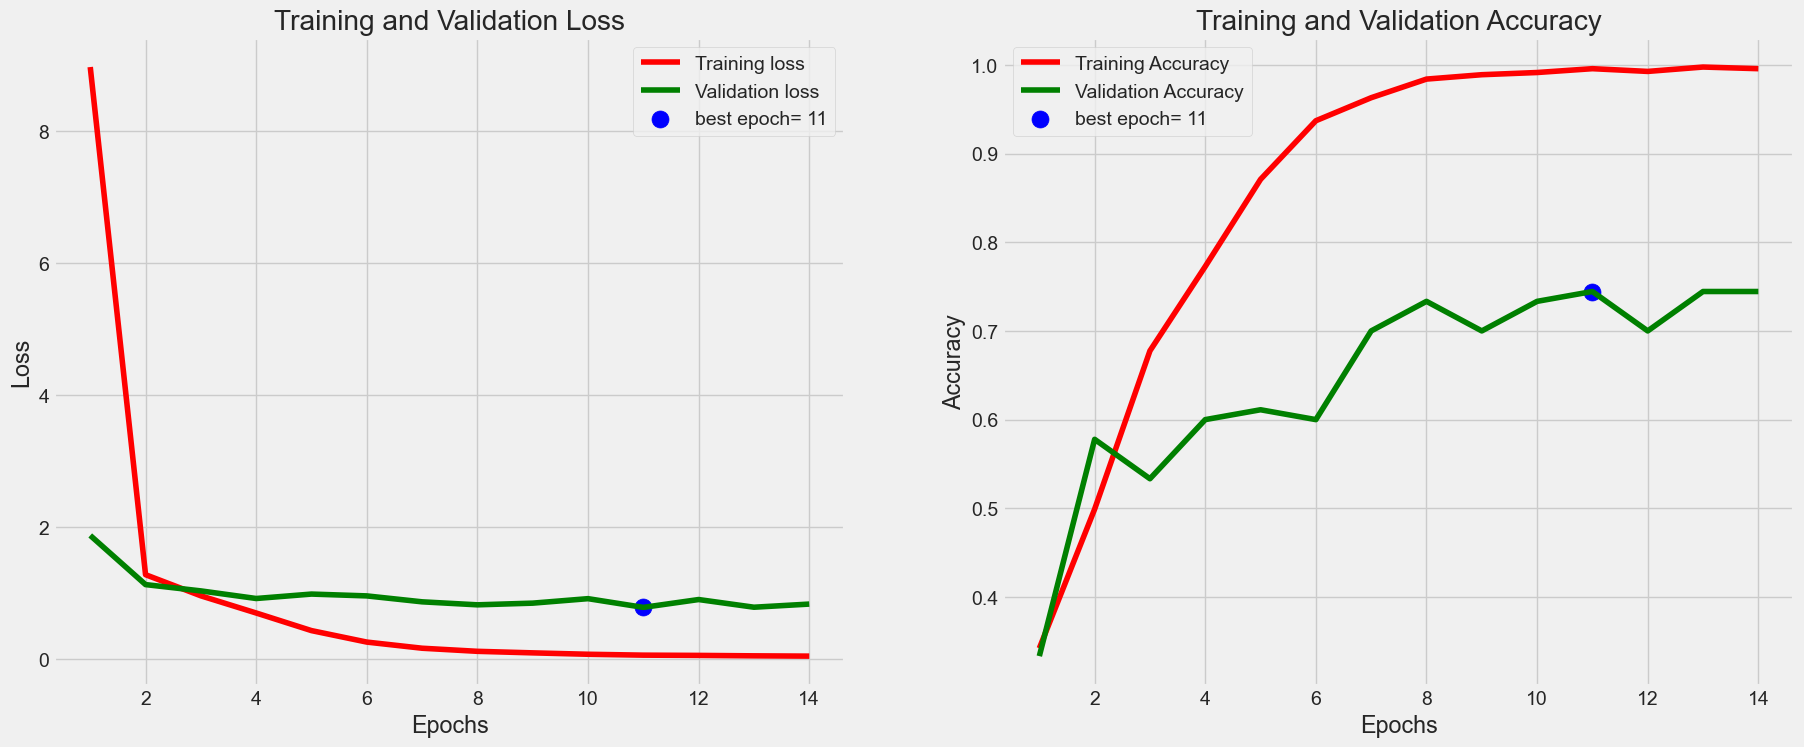

2/2 [==============================] - 1s 126ms/step - loss: 0.7155 - accuracy: 0.7333
accuracy on the test set is 73.33 %



In [25]:
tr_plot(history,0)
save_dir=r'./'
subject='pest'
acc=model.evaluate( test_gen, batch_size=test_batch_size, verbose=1, steps=test_steps, return_dict=False)[1]*100
msg=f'accuracy on the test set is {acc:5.2f} %'
print_in_color(msg, (0,255,0),(55,65,80))
save_id=str (model_name +  '-' + subject +'-'+ str(acc)[:str(acc).rfind('.')+3] + '.keras')
save_loc=os.path.join(save_dir, save_id)
model.save(save_loc)

### define function to generate the confusion matrix and classification report

In [26]:
def print_info( test_gen, preds, print_code, save_dir, subject ):
    class_dict=test_gen.class_indices
    labels= test_gen.labels
    file_names= test_gen.filenames 
    error_list=[]
    true_class=[]
    pred_class=[]
    prob_list=[]
    new_dict={}
    error_indices=[]
    y_pred=[]
    for key,value in class_dict.items():
        new_dict[value]=key             # dictionary {integer of class number: string of class name}
    # store new_dict as a text fine in the save_dir
    classes=list(new_dict.values())     # list of string of class names
    dict_as_text=str(new_dict)
    dict_name= subject + '-' +str(len(classes)) +'.txt'  
    dict_path=os.path.join(save_dir,dict_name)    
    with open(dict_path, 'w') as x_file:
        x_file.write(dict_as_text)    
    errors=0      
    for i, p in enumerate(preds):
        pred_index=np.argmax(p)        
        true_index=labels[i]  # labels are integer values
        if pred_index != true_index: # a misclassification has occurred
            error_list.append(file_names[i])
            true_class.append(new_dict[true_index])
            pred_class.append(new_dict[pred_index])
            prob_list.append(p[pred_index])
            error_indices.append(true_index)            
            errors=errors + 1
        y_pred.append(pred_index)    
    if print_code !=0:
        if errors>0:
            if print_code>errors:
                r=errors
            else:
                r=print_code           
            msg='{0:^28s}{1:^28s}{2:^28s}{3:^16s}'.format('Filename', 'Predicted Class' , 'True Class', 'Probability')
            print_in_color(msg, (0,255,0),(55,65,80))
            for i in range(r):                
                split1=os.path.split(error_list[i])                
                split2=os.path.split(split1[0])                
                fname=split2[1] + '/' + split1[1]
                msg='{0:^28s}{1:^28s}{2:^28s}{3:4s}{4:^6.4f}'.format(fname, pred_class[i],true_class[i], ' ', prob_list[i])
                print_in_color(msg, (255,255,255), (55,65,60))
                #print(error_list[i]  , pred_class[i], true_class[i], prob_list[i])               
        else:
            msg='With accuracy of 100 % there are no errors to print'
            print_in_color(msg, (0,255,0),(55,65,80))
    if errors>0:
        plot_bar=[]
        plot_class=[]
        for  key, value in new_dict.items():        
            count=error_indices.count(key) 
            if count!=0:
                plot_bar.append(count) # list containg how many times a class c had an error
                plot_class.append(value)   # stores the class 
        fig=plt.figure()
        fig.set_figheight(len(plot_class)/3)
        fig.set_figwidth(10)
        plt.style.use('fivethirtyeight')
        for i in range(0, len(plot_class)):
            c=plot_class[i]
            x=plot_bar[i]
            plt.barh(c, x, )
            plt.title( ' Errors by Class on Test Set')
    y_true= np.array(labels)        
    y_pred=np.array(y_pred)
    if len(classes)<= 30:
        # create a confusion matrix 
        cm = confusion_matrix(y_true, y_pred )        
        length=len(classes)
        if length<8:
            fig_width=8
            fig_height=8
        else:
            fig_width= int(length * .5)
            fig_height= int(length * .5)
        plt.figure(figsize=(fig_width, fig_height))
        sns.heatmap(cm, annot=True, vmin=0, fmt='g', cmap='Blues', cbar=False)       
        plt.xticks(np.arange(length)+.5, classes, rotation= 90)
        plt.yticks(np.arange(length)+.5, classes, rotation=0)
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title("Confusion Matrix")
        plt.show()
    clr = classification_report(y_true, y_pred, target_names=classes)
    print("Classification Report:\n----------------------\n", clr)

### make predictions on test set and generate confusion matrix and classification report

2/2 [==============================] - 1s 292ms/step


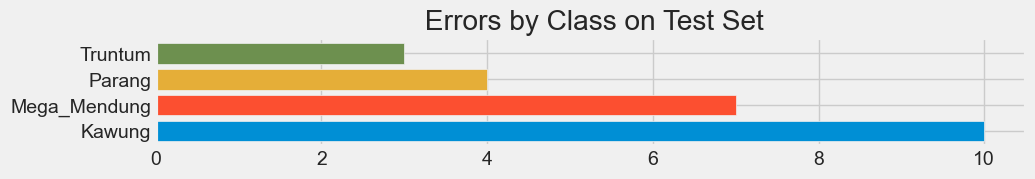

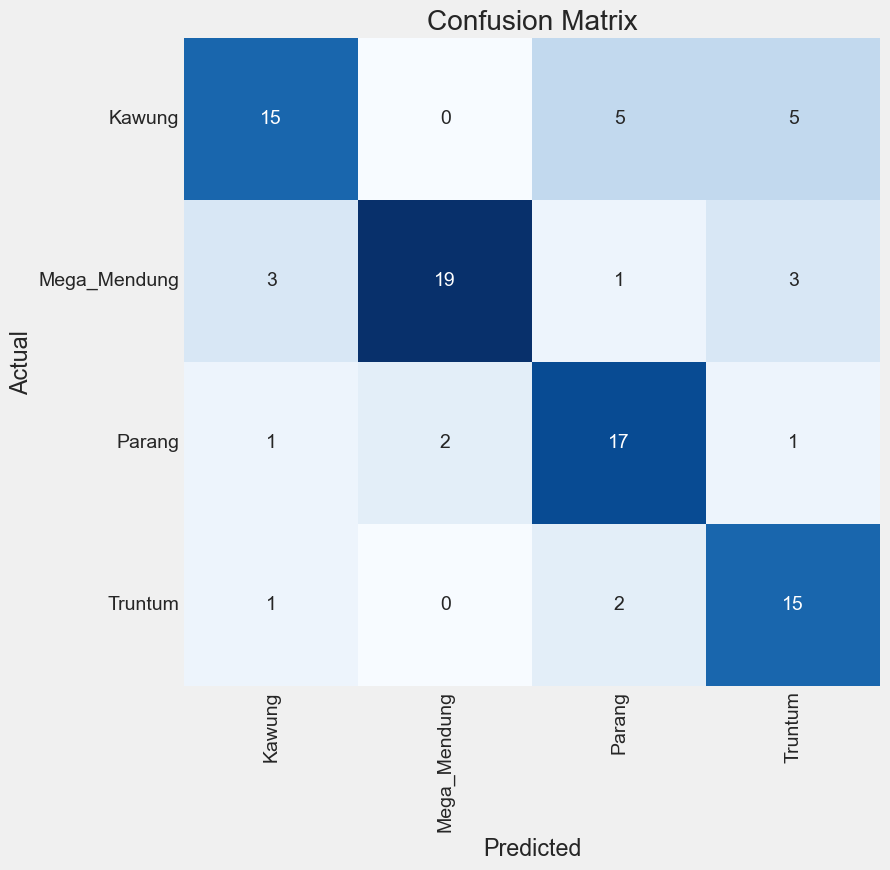

Classification Report:
----------------------
               precision    recall  f1-score   support

      Kawung       0.75      0.60      0.67        25
Mega_Mendung       0.90      0.73      0.81        26
      Parang       0.68      0.81      0.74        21
     Truntum       0.62      0.83      0.71        18

    accuracy                           0.73        90
   macro avg       0.74      0.74      0.73        90
weighted avg       0.75      0.73      0.73        90



In [27]:
print_code=0
preds=model.predict(test_gen) 
print_info( test_gen, preds, print_code, save_dir, subject )  

In [1]:
model.save("scratchCNN_V3.keras")


NameError: name 'model' is not defined

1/1 [==============================] - 0s 22ms/step


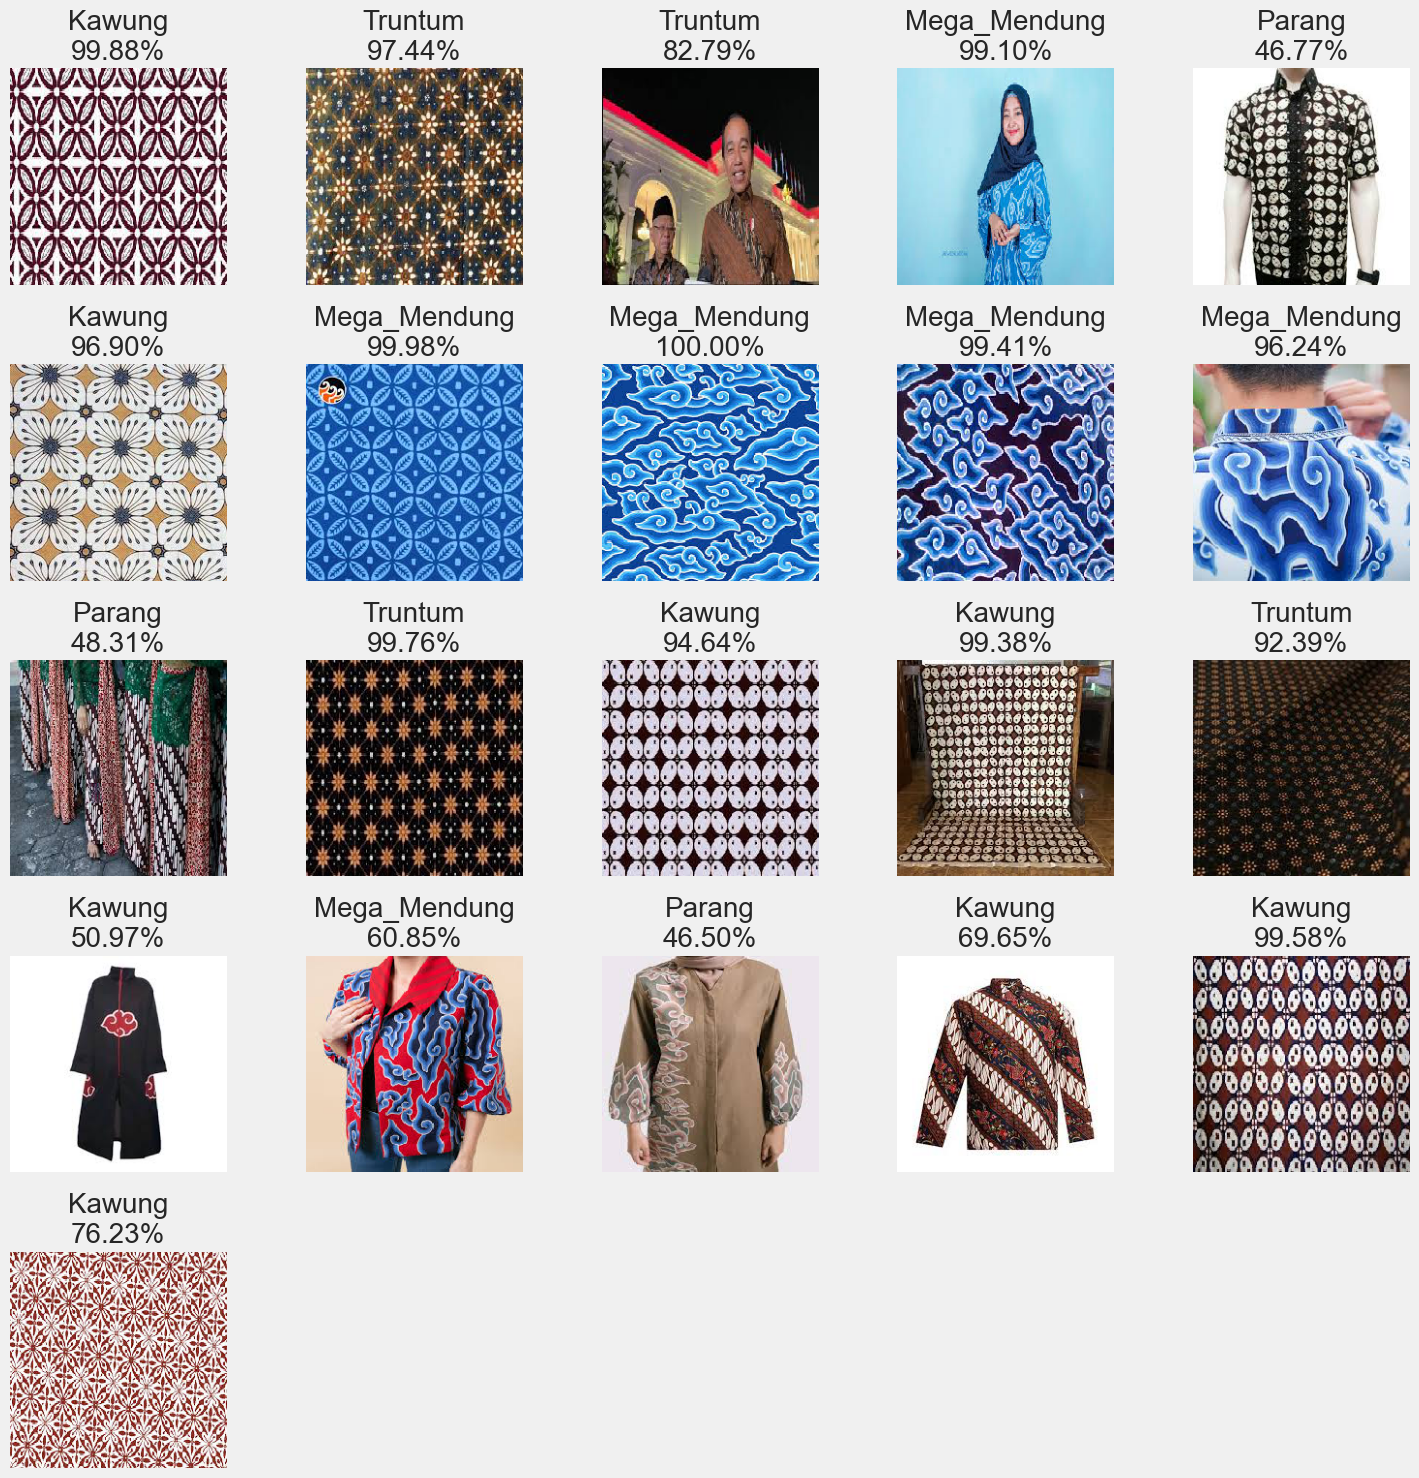

In [31]:
import tensorflow as tf
from tensorflow.keras.models import load_model
import numpy as np
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Load model yang telah disimpan
model_path = 'scratchCNN.keras'
model = load_model(model_path)

# Daftar kelas (urutan sesuai training)
class_names = ['Kawung', 'Mega_Mendung', 'Parang', 'Truntum']

# Path folder gambar uji (di luar dataset training/valid/test)
test_image_dir = r'C:\Users\hp\Computer Vision\Project Akhir Computer Vision\Batik-CNN\external_test'  # Ganti dengan path kamu

img_height, img_width = 224, 224

# Ambil maksimal 25 gambar
image_files = [f for f in os.listdir(test_image_dir) if f.lower().endswith(('jpg', 'jpeg', 'png'))]
image_files = image_files[:25]  # Maksimal 25

plt.figure(figsize=(15, 15))

for idx, img_name in enumerate(image_files):
    img_path = os.path.join(test_image_dir, img_name)
    
    # Load dan preprocess gambar
    img = image.load_img(img_path, target_size=(img_height, img_width))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Prediksi
    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions)]
    confidence = np.max(predictions) * 100

    # Plot
    plt.subplot(5, 5, idx + 1)
    plt.imshow(img)
    plt.title(f"{predicted_class}\n{confidence:.2f}%", fontsize=20)
    plt.axis('off')

plt.tight_layout()
plt.show()
